# 1. Set-Up Environment

In [1]:
# import library untuk manipulasi data dan visualisasi
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display

# import modul preprocessing, pipeline, pemodelan gaussianNB, dan evaluasi model dari scikit-learn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score, roc_curve, precision_recall_fscore_support)

In [ ]:
# menampilkan versi library yang digunakan
import sys, platform, sklearn, matplotlib, seaborn
from datetime import date

env = {'Python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
       'scikit-learn': sklearn.__version__, 'matplotlib': matplotlib.__version__, 'seaborn': seaborn.__version__,
       'Tanggal eksekusi': date.today().isoformat()}
display(pd.DataFrame(env, index=['Versi']).T)

,Versi
Python,3.14.7
pandas,3.1.1
numpy,2.5.5
scikit-learn,1.9.1
matplotlib,3.11.2
seaborn,0.13.2
Tanggal eksekusi,2026-11-23


In [3]:
# pengaturan tampilan tabel & grafik
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_style('whitegrid')

# menetapkan seed agar hasil pembagian data dan pemodelan konsisten
RANDOM_STATE = 42

# 2. Memahami Karakteristik Dataset 

In [4]:
# membaca dataset
df = pd.read_csv('credit_risk_dataset.csv')
print(f"Dimensi Awal Dataset : {df.shape[0]} baris x { df.shape[1]} kolom\n")

Dimensi Awal Dataset : 32581 baris x 12 kolom



In [5]:
# menampilkan sampel 5 baris pertama dataset
print("A. Sampel 5 Baris Pertama Dataset Asli")
display(df.head())

A. Sampel 5 Baris Pertama Dataset Asli


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [6]:
# menampilkan informasi tipe data dan missing values
print("\nB. Informasi Tipe Data & Missing Values")
info_df = pd.DataFrame({'Tipe': df.dtypes.astype(str), 'Missing': df.isnull().sum(), 'Missing (%)': (df.isnull().mean()*100).round(2), 'Unik': df.nunique()})
display(info_df)


B. Informasi Tipe Data & Missing Values


,Tipe,Missing,Missing (%),Unik
person_age,int64,0,0.00,58
person_income,int64,0,0.00,4295
person_home_ownership,str,0,0.00,4
person_emp_length,float64,895,2.75,36
loan_intent,str,0,0.00,6
loan_grade,str,0,0.00,7
loan_amnt,int64,0,0.00,753
loan_int_rate,float64,3116,9.56,348
loan_status,int64,0,0.00,2
loan_percent_income,float64,0,0.00,77


In [7]:
# menampilkan statistik deskriptif fitur numerik
print("\nC. Statistik Deskriptif Fitur Numerik (Sebelum Cleaning)")
display(df.describe().round(2))


C. Statistik Deskriptif Fitur Numerik (Sebelum Cleaning)


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,31686.00,32581.00,29465.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.79,9589.37,11.01,0.22,0.17,5.80
std,6.35,61983.12,4.14,6322.09,3.24,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,7.90,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.47,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


In [8]:
# distribusi target + baseline "tebak kelas mayoritas"
dist = df['loan_status'].value_counts().rename({0:'0 (Lancar)',1:'1 (Gagal Bayar)'})
display(pd.DataFrame({'Jumlah': dist, '%': (dist/len(df)*100).round(2)}))
print(f"Baseline accuracy (selalu menebak 'Lancar'): {df['loan_status'].value_counts(normalize=True).max()*100:.2f}%")

,Jumlah,%
loan_status,,
0 (Lancar),25473,78.18
1 (Gagal Bayar),7108,21.82


Baseline accuracy (selalu menebak 'Lancar'): 78.18%


In [9]:
# nilai kategori: cek ejaan/spasi/huruf besar-kecil
for c in ['person_home_ownership','loan_intent','loan_grade','cb_person_default_on_file']:
    print(c, '->', sorted(df[c].astype(str).unique()))

person_home_ownership -> ['MORTGAGE', 'OTHER', 'OWN', 'RENT']
loan_intent -> ['DEBTCONSOLIDATION', 'EDUCATION', 'HOMEIMPROVEMENT', 'MEDICAL', 'PERSONAL', 'VENTURE']
loan_grade -> ['A', 'B', 'C', 'D', 'E', 'F', 'G']
cb_person_default_on_file -> ['N', 'Y']


In [10]:
# AUDIT ANOMALI (belum ada data yang dihapus di sel ini)
def audit_rules(d):
    return {
      'Usia > 80 tahun'                               : d['person_age'] > 80,
      'Masa kerja > 60 tahun'                         : d['person_emp_length'] > 60,
      'Mulai kerja sebelum usia 14 (usia - masa kerja < 14)': (d['person_age'] - d['person_emp_length']) < 14,
      'Riwayat kredit dimulai sebelum usia 16'        : (d['person_age'] - d['cb_person_cred_hist_length']) < 16,
      'loan_percent_income tidak sesuai loan_amnt/income': (d['loan_amnt']/d['person_income'] - d['loan_percent_income']).abs() > 0.01,
      'Income <= 0 atau loan_amnt <= 0'               : (d['person_income'] <= 0) | (d['loan_amnt'] <= 0),
    }

print(f"Baris duplikat persis: {df.duplicated().sum()}")
d0 = df.drop_duplicates()
rules = audit_rules(d0)
display(pd.DataFrame({'Jumlah baris': {k: int(v.sum()) for k, v in rules.items()}}))
print(f"Income > 1.000.000 (ekstrem, hanya dilaporkan): {(d0['person_income'] > 1_000_000).sum()} baris")

# apakah data missing 'acak'? bandingkan rasio gagal bayar
print("\nRasio gagal bayar berdasarkan loan_int_rate kosong / terisi:")
print(d0.groupby(d0['loan_int_rate'].isna())['loan_status'].mean().round(4).rename({False:'terisi', True:'kosong'}))

Baris duplikat persis: 165


,Jumlah baris
Usia > 80 tahun,7
Masa kerja > 60 tahun,2
Mulai kerja sebelum usia 14 (usia - masa kerja < 14),2
Riwayat kredit dimulai sebelum usia 16,0
loan_percent_income tidak sesuai loan_amnt/income,387
Income <= 0 atau loan_amnt <= 0,0


Income > 1.000.000 (ekstrem, hanya dilaporkan): 9 baris

Rasio gagal bayar berdasarkan loan_int_rate kosong / terisi:
loan_int_rate
terisi    0.2199
kosong    0.2071
Name: loan_status, dtype: float64


# 3. Data Preprocessing & Data Cleaning 

In [11]:
# membuat salinan dataset untuk proses cleaning
df_clean = df.copy()
log_rows = []

In [12]:
# rapikan teks kategori
for c in ['person_home_ownership','loan_intent','loan_grade','cb_person_default_on_file']:
    df_clean[c] = df_clean[c].astype(str).str.strip().str.upper()

In [13]:
# menghapus baris duplikat
n = len(df_clean); df_clean = df_clean.drop_duplicates()
log_rows.append(('Duplikat persis', n - len(df_clean)))

In [14]:
# hapus data mustahil
DROP_RULES = [
    'Usia > 80 tahun',
    'Masa kerja > 60 tahun',
    'Mulai kerja sebelum usia 14 (usia - masa kerja < 14)',
    'Riwayat kredit dimulai sebelum usia 16',
    'loan_percent_income tidak sesuai loan_amnt/income',
    'Income <= 0 atau loan_amnt <= 0',
]
for name in DROP_RULES:
    mask = audit_rules(df_clean)[name]
    log_rows.append((name, int(mask.sum())))
    df_clean = df_clean[~mask]
df_clean = df_clean.reset_index(drop=True)

display(pd.DataFrame(log_rows, columns=['Tahap cleaning','Baris dibuang']))

print(f"Total: {len(df)} -> {len(df_clean)} baris | Missing tersisa (akan diimputasi di pipeline):")
print(df_clean.isnull().sum()[lambda s: s > 0].to_string())

,Tahap cleaning,Baris dibuang
0,Duplikat persis,165
1,Usia > 80 tahun,7
2,Masa kerja > 60 tahun,2
3,Mulai kerja sebelum usia 14 (usia - masa kerja...,0
4,Riwayat kredit dimulai sebelum usia 16,0
5,loan_percent_income tidak sesuai loan_amnt/income,387
6,Income <= 0 atau loan_amnt <= 0,0


Total: 32581 -> 32020 baris | Missing tersisa (akan diimputasi di pipeline):
person_emp_length     884
loan_int_rate        3058


In [15]:
# encoding. Tidak memakai statistik data
df_enc = df_clean.copy()
df_enc['loan_grade'] = df_enc['loan_grade'].map({'A':0,'B':1,'C':2,'D':3,'E':4,'F':5,'G':6})
df_enc['cb_person_default_on_file'] = df_enc['cb_person_default_on_file'].map({'N':0,'Y':1})
df_enc = pd.get_dummies(df_enc, columns=['person_home_ownership','loan_intent'], drop_first=True, dtype=int)

X = df_enc.drop(columns='loan_status')
y = df_enc['loan_status']
assert X.drop(columns=['person_emp_length','loan_int_rate']).isnull().sum().sum() == 0
print(f"X: {X.shape} | y: {y.shape} | kelas gagal bayar: {y.mean()*100:.2f}%")

X: (32020, 17) | y: (32020,) | kelas gagal bayar: 20.93%


In [16]:
# cek asumsi independensi naive bayes (pasangan fitur numerik yang berkorelasi kuat)
num_cols = ['person_age','person_income','person_emp_length','loan_amnt','loan_int_rate',
            'loan_percent_income','cb_person_cred_hist_length','loan_grade']
corr = df_enc[num_cols].corr()
pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
             .rename('korelasi').reset_index().query('abs(korelasi) >= 0.5')
             .sort_values('korelasi', key=abs, ascending=False))
display(pairs)
print("Pasangan di atas melanggar asumsi 'naive' -> probabilitas model cenderung terlalu ekstrem.")

,level_0,level_1,korelasi
39,loan_int_rate,loan_grade,0.932892
6,person_age,cb_person_cred_hist_length,0.878763
29,loan_amnt,loan_percent_income,0.572911


Pasangan di atas melanggar asumsi 'naive' -> probabilitas model cenderung terlalu ekstrem.


# 4. Menganalisis Pola Pinjaman dan Risiko Gagal Bayar

In [23]:
# menganalisis rasio gagal bayar menurut kategori fitur
def rate_table(col, order=None):
    t = df_clean.groupby(col)['loan_status'].agg(Jumlah='count', Gagal_Bayar_pct=lambda s: round(s.mean()*100, 2))
    return t.sort_values('Gagal_Bayar_pct', ascending=False) if order is None else t.loc[order]

bins = [0, .10, .15, .20, .25, .30, .40, 1]
df_clean['dti_bin'] = pd.cut(df_clean['loan_percent_income'], bins, include_lowest=True)

for title, t in [('Grade', rate_table('loan_grade')), ('Tujuan pinjaman', rate_table('loan_intent')),
                 ('Status rumah', rate_table('person_home_ownership')),
                 ('Rasio pinjaman/pendapatan', df_clean.groupby('dti_bin', observed=True)['loan_status']
                      .agg(Jumlah='count', Gagal_Bayar_pct=lambda s: round(s.mean()*100, 2)))]:
    print(f"\nGagal bayar (%) menurut {title}"); display(t)

display(df_clean.groupby('loan_status')[['person_age','person_income','person_emp_length','loan_amnt',
        'loan_int_rate','loan_percent_income']].mean().round(2))


Gagal bayar (%) menurut Grade


,Jumlah,Gagal_Bayar_pct
loan_grade,,
G,61,98.36
F,215,66.98
E,896,61.83
D,3429,56.78
C,6398,20.30
B,10339,15.96
A,10682,9.80



Gagal bayar (%) menurut Tujuan pinjaman


,Jumlah,Gagal_Bayar_pct
loan_intent,,
DEBTCONSOLIDATION,5189,28.68
HOMEIMPROVEMENT,3594,26.15
MEDICAL,5654,21.75
PERSONAL,5495,19.89
EDUCATION,6409,17.26
VENTURE,5679,14.86



Gagal bayar (%) menurut Status rumah


,Jumlah,Gagal_Bayar_pct
person_home_ownership,,
RENT,16217,30.96
OTHER,104,29.81
MORTGAGE,13143,11.15
OWN,2556,7.24



Gagal bayar (%) menurut Rasio pinjaman/pendapatan


,Jumlah,Gagal_Bayar_pct
dti_bin,,
"(-0.001, 0.1]",10341,11.03
"(0.1, 0.15]",6578,11.77
"(0.15, 0.2]",5262,16.78
"(0.2, 0.25]",3683,18.44
"(0.25, 0.3]",2381,24.28
"(0.3, 0.4]",2665,68.48
"(0.4, 1.0]",1110,73.96


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income
loan_status,,,,,,
0,27.80,70598.24,4.97,9239.41,10.44,0.15
1,27.43,47290.83,4.03,10530.40,12.95,0.25


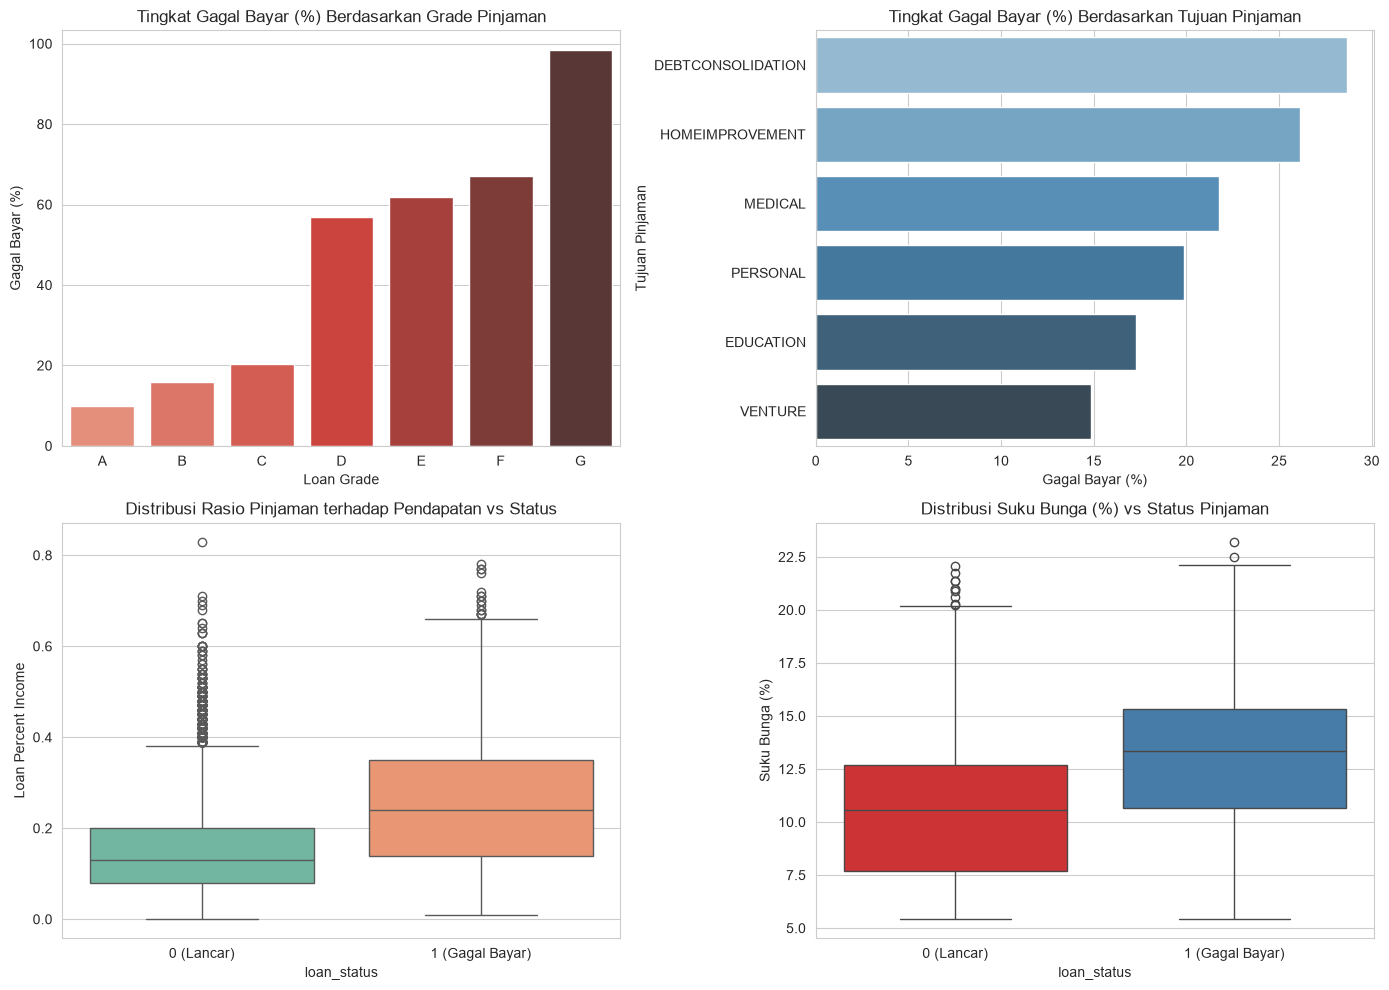

In [24]:
# visualisasi pola pinjaman dan gagal bayar
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
g = rate_table('loan_grade', order=sorted(df_clean['loan_grade'].unique()))
i = rate_table('loan_intent')
d = df_clean.groupby('dti_bin', observed=True)['loan_status'].mean()*100

# Plot 1: Tambahkan hue dan legend=False
sns.barplot(x=g.index, y=g['Gagal_Bayar_pct'], hue=g.index, ax=axes[0, 0], palette='Reds_d', legend=False)
axes[0, 0].set_title('Tingkat Gagal Bayar (%) Berdasarkan Grade Pinjaman')
axes[0, 0].set_ylabel('Gagal Bayar (%)')
axes[0, 0].set_xlabel('Loan Grade')

# Plot 2: Tambahkan hue dan legend=False
sns.barplot(y=i.index, x=i['Gagal_Bayar_pct'], hue=i.index, ax=axes[0, 1], palette='Blues_d', legend=False)
axes[0, 1].set_title('Tingkat Gagal Bayar (%) Berdasarkan Tujuan Pinjaman')
axes[0, 1].set_xlabel('Gagal Bayar (%)')
axes[0, 1].set_ylabel('Tujuan Pinjaman')

# Plot 3: Tambahkan hue, legend=False, dan set_xticks([0, 1])
sns.boxplot(x='loan_status', y='loan_percent_income', hue='loan_status', data=df_clean, ax=axes[1, 0], palette='Set2', legend=False)
axes[1, 0].set_title('Distribusi Rasio Pinjaman terhadap Pendapatan vs Status')
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_xticklabels(['0 (Lancar)', '1 (Gagal Bayar)'])
axes[1, 0].set_ylabel('Loan Percent Income')

# Plot 4: Tambahkan hue, legend=False, dan set_xticks([0, 1])
sns.boxplot(x='loan_status', y='loan_int_rate', hue='loan_status', data=df_clean, ax=axes[1, 1], palette='Set1', legend=False)
axes[1, 1].set_title('Distribusi Suku Bunga (%) vs Status Pinjaman')
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(['0 (Lancar)', '1 (Gagal Bayar)'])
axes[1, 1].set_ylabel('Suku Bunga (%)')

plt.tight_layout()
plt.show()

# 5. Gaussian Naive Bayes Modeling & Evaluasi 10-Fold CV

In [25]:
from sklearn.metrics import average_precision_score, precision_recall_curve

LOG_COLS = ['person_income', 'loan_amnt']
IMP_COLS = ['person_emp_length', 'loan_int_rate']

def make_pipeline():
    imputer = ColumnTransformer([('imp', SimpleImputer(strategy='median'), IMP_COLS)],
                                remainder='passthrough', verbose_feature_names_out=False).set_output(transform='pandas')
    logger = ColumnTransformer([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one'), LOG_COLS)],
                               remainder='passthrough', verbose_feature_names_out=False).set_output(transform='pandas')
    return Pipeline([('imputer', imputer), ('log', logger), ('gnb', GaussianNB())])

pipe = make_pipeline()
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision']   # + average_precision
cv = cross_validate(pipe, X, y, cv=skf, scoring=scoring)

fold_df = pd.DataFrame({m: cv[f'test_{m}'] for m in scoring}, index=[f'Fold-{i}' for i in range(1, 11)])
display((fold_df * 100).round(2).assign(roc_auc=fold_df['roc_auc'].round(4),
                                        average_precision=fold_df['average_precision'].round(4)))
summary = pd.DataFrame({'Rata-rata': fold_df.mean(), 'Std': fold_df.std()}).round(4)
display(summary)
print(f"Pembanding: baseline accuracy {max(y.mean(), 1 - y.mean())*100:.2f}% | baseline Average Precision "
      f"(= proporsi gagal bayar) {y.mean():.4f}")

,accuracy,precision,recall,f1,roc_auc,average_precision
Fold-1,84.20,60.38,71.19,65.34,0.8643,0.6564
Fold-2,83.51,59.37,67.16,63.03,0.8518,0.6361
Fold-3,82.35,56.64,66.87,61.33,0.8438,0.6144
Fold-4,82.85,57.89,66.27,61.80,0.8464,0.6361
Fold-5,83.76,59.15,72.39,65.10,0.8683,0.6594
Fold-6,83.39,58.98,67.61,63.00,0.8546,0.6347
Fold-7,82.45,57.09,64.93,60.75,0.8406,0.6003
Fold-8,83.32,58.97,66.72,62.61,0.8532,0.6396
Fold-9,81.73,55.29,66.27,60.29,0.8481,0.6171
Fold-10,83.04,58.84,63.49,61.08,0.8399,0.6228


,Rata-rata,Std
accuracy,0.8306,0.0073
precision,0.5826,0.0152
recall,0.6729,0.0267
f1,0.6243,0.0174
roc_auc,0.8511,0.0095
average_precision,0.6317,0.0184


Pembanding: baseline accuracy 79.07% | baseline Average Precision (= proporsi gagal bayar) 0.2093


                 precision    recall  f1-score   support

     0 (Lancar)     0.9097    0.8723    0.8906     25319
1 (Gagal Bayar)     0.5825    0.6729    0.6244      6701

       accuracy                         0.8306     32020
      macro avg     0.7461    0.7726    0.7575     32020
   weighted avg     0.8412    0.8306    0.8349     32020

ROC-AUC (OOF): 0.8511 | Average Precision (OOF): 0.6305 | baseline AP: 0.2093


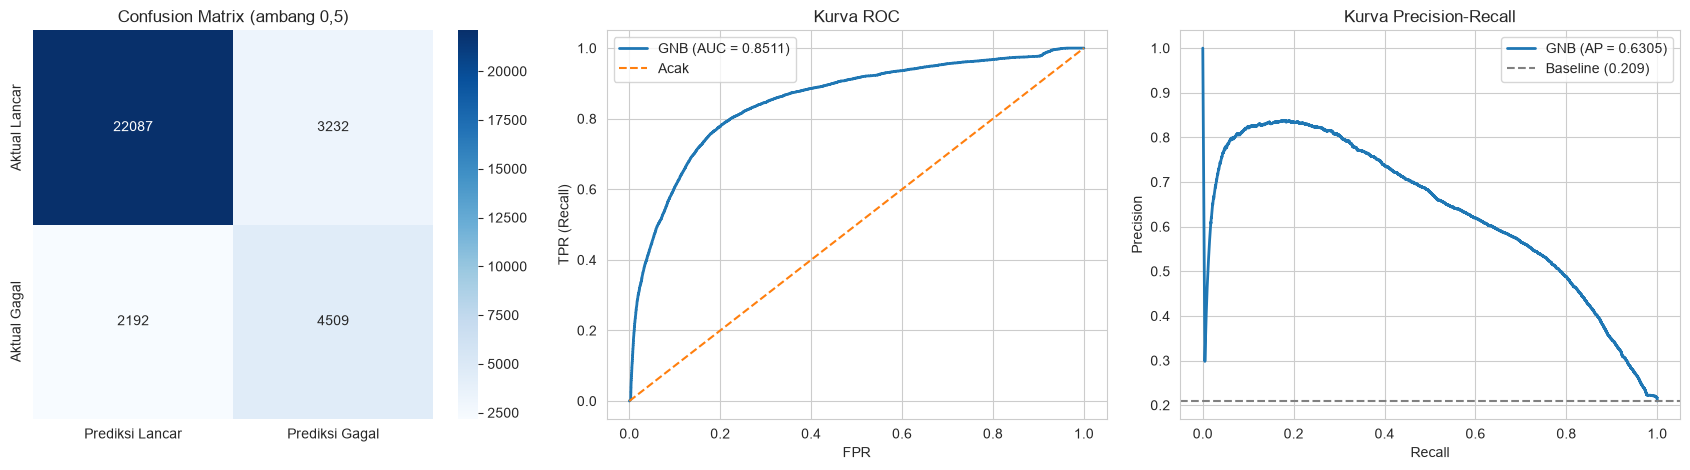

False Positive: 3232 | False Negative: 2192


In [26]:
proba_oof = cross_val_predict(pipe, X, y, cv=skf, method='predict_proba')[:, 1]
pred_oof = (proba_oof >= 0.5).astype(int)

print(classification_report(y, pred_oof, target_names=['0 (Lancar)', '1 (Gagal Bayar)'], digits=4))
cm = confusion_matrix(y, pred_oof)
fpr, tpr, _ = roc_curve(y, proba_oof)
prec_c, rec_c, _ = precision_recall_curve(y, proba_oof)
ap_oof = average_precision_score(y, proba_oof)
print(f'ROC-AUC (OOF): {roc_auc_score(y, proba_oof):.4f} | Average Precision (OOF): {ap_oof:.4f} '
      f'| baseline AP: {y.mean():.4f}')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=['Prediksi Lancar', 'Prediksi Gagal'], yticklabels=['Aktual Lancar', 'Aktual Gagal'])
ax[0].set_title('Confusion Matrix (ambang 0,5)')
ax[1].plot(fpr, tpr, lw=2, label=f'GNB (AUC = {roc_auc_score(y, proba_oof):.4f})')
ax[1].plot([0, 1], [0, 1], '--', label='Acak'); ax[1].legend(); ax[1].set_title('Kurva ROC')
ax[1].set_xlabel('FPR'); ax[1].set_ylabel('TPR (Recall)')
ax[2].plot(rec_c, prec_c, lw=2, label=f'GNB (AP = {ap_oof:.4f})')
ax[2].axhline(y.mean(), ls='--', color='gray', label=f'Baseline ({y.mean():.3f})')
ax[2].legend(); ax[2].set_title('Kurva Precision-Recall'); ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precision')
plt.tight_layout(); plt.show()
print(f"False Positive: {cm[0,1]} | False Negative: {cm[1,0]}")

In [ ]:
# seberapa ekstrem skor GNB? Bila hampir semua skor dekat 0 atau 1, ambang 0,3-0,6 hampir tidak mengubah hasil.
tengah = ((proba_oof > 0.05) & (proba_oof < 0.95)).mean() * 100
print(f'Skor di antara 0,05 dan 0,95: {tengah:.1f}% dari seluruh data')

# tabel ambang pada seluruh prediksi out-of-fold
grid = [0.01, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.99]
rows = []
for t in grid:
    pr = (proba_oof >= t).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y, pr, average='binary', zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, pr).ravel()
    rows.append({'Ambang': t, 'Precision': p, 'Recall': r, 'F1': f, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
                 'Ditandai berisiko (%)': pr.mean() * 100})
thr_df = pd.DataFrame(rows).round(4)
display(thr_df)

Skor di antara 0,05 dan 0,95: 44.0% dari seluruh data


,Ambang,Precision,Recall,F1,TP,FP,FN,TN,Ditandai berisiko (%)
0,0.01,0.2732,0.9494,0.4243,6362,16925,339,8394,72.7264
1,0.05,0.3534,0.8948,0.5067,5996,10969,705,14350,52.9825
2,0.10,0.4110,0.8602,0.5562,5764,8262,937,17057,43.8039
3,0.20,0.4770,0.8076,0.5998,5412,5934,1289,19385,35.4341
4,0.30,0.5217,0.7635,0.6198,5116,4691,1585,20628,30.6277
5,0.40,0.5535,0.7200,0.6259,4825,3893,1876,21426,27.2267
6,0.50,0.5825,0.6729,0.6244,4509,3232,2192,22087,24.1755
7,0.60,0.6059,0.6242,0.6149,4183,2721,2518,22598,21.5615
8,0.70,0.6343,0.5722,0.6016,3834,2210,2867,23109,18.8757
9,0.80,0.6704,0.5066,0.5771,3395,1669,3306,23650,15.8151


In [ ]:
# memilih ambang tanpa 'mengintip': ambang dipilih pada fold 1-5, lalu dilaporkan pada fold 6-10.
# setiap baris memiliki skor out-of-fold, sehingga kedua kelompok ini tidak saling bocor.
fold_id = np.zeros(len(y), dtype=int)
for k, (_, te) in enumerate(skf.split(X, y)):
    fold_id[te] = k
tune, hold = fold_id < 5, fold_id >= 5
yv = y.values

COST_FN, COST_FP = 5, 1      
fine = np.round(np.arange(0.01, 1.0, 0.01), 2)

def f1_at(t, m):
    return precision_recall_fscore_support(yv[m], (proba_oof[m] >= t).astype(int), average='binary', zero_division=0)[2]
def cost_at(t, m):
    pr = proba_oof[m] >= t
    return COST_FN * ((~pr) & (yv[m] == 1)).sum() + COST_FP * (pr & (yv[m] == 0)).sum()

t_f1 = max(fine, key=lambda t: f1_at(t, tune))
t_cost = min(fine, key=lambda t: cost_at(t, tune))

hasil = []
for nama, t in [('Bawaan (0,50)', 0.50), ('Ambang F1 tertinggi', t_f1), (f'Ambang biaya minimum (FN:FP = {COST_FN}:{COST_FP})', t_cost)]:
    pr = (proba_oof[hold] >= t).astype(int)
    p, r, f, _ = precision_recall_fscore_support(yv[hold], pr, average='binary', zero_division=0)
    tn, fp, fn, tp = confusion_matrix(yv[hold], pr).ravel()
    hasil.append({'Skenario': nama, 'Ambang': t, 'Precision': p, 'Recall': r, 'F1': f,
                  'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn, 'Total biaya': COST_FN * fn + COST_FP * fp})
display(pd.DataFrame(hasil).round(4))
print('Ambang dipilih pada fold 1-5; seluruh angka di atas dihitung pada fold 6-10 (data yang tidak dipakai memilih ambang).')

,Skenario,Ambang,Precision,Recall,F1,TP,FP,FN,TN,Total biaya
0,"Bawaan (0,50)",0.50,0.578,0.6580,0.6154,2205,1610,1146,11049,7340
1,Ambang F1 tertinggi,0.47,0.570,0.6741,0.6177,2259,1704,1092,10955,7164
2,Ambang biaya minimum (FN:FP = 5:1),0.21,0.481,0.7971,0.6000,2671,2882,680,9777,6282


Ambang dipilih pada fold 1-5; seluruh angka di atas dihitung pada fold 6-10 (data yang tidak dipakai memilih ambang).


# 6. Menentukan Faktor yang Paling Berpengaruh

In [29]:
# fitur penting (feature importance) berdasarkan penurunan AUC
groups = {'person_home_ownership': [c for c in X.columns if c.startswith('person_home_ownership_')],
          'loan_intent':           [c for c in X.columns if c.startswith('loan_intent_')]}
grouped = {c for v in groups.values() for c in v}
groups.update({c: [c] for c in X.columns if c not in grouped})

rng = np.random.default_rng(RANDOM_STATE)
N_REPEATS = 5
imp = {g: [] for g in groups}
for tr, te in skf.split(X, y):
    m = clone(pipe).fit(X.iloc[tr], y.iloc[tr])
    Xte, yte = X.iloc[te], y.iloc[te]
    base = roc_auc_score(yte, m.predict_proba(Xte)[:, 1])
    for g, cols in groups.items():
        drops = []
        for _ in range(N_REPEATS):
            Xp = Xte.copy()
            Xp[cols] = Xte[cols].values[rng.permutation(len(Xte))]   # acak satu grup sekaligus
            drops.append(base - roc_auc_score(yte, m.predict_proba(Xp)[:, 1]))
        imp[g].append(np.mean(drops))

importance_df = (pd.DataFrame({'Faktor': list(imp), 'Penurunan_AUC': [np.mean(v) for v in imp.values()],
                               'Std_antar_fold': [np.std(v) for v in imp.values()]})
                 .sort_values('Penurunan_AUC', ascending=False).reset_index(drop=True))
display(importance_df.round(4))

,Faktor,Penurunan_AUC,Std_antar_fold
0,loan_percent_income,0.0689,0.0035
1,person_home_ownership,0.0623,0.0057
2,loan_grade,0.0286,0.0030
3,person_income,0.0266,0.0022
4,loan_intent,0.0117,0.0025
5,loan_int_rate,0.0100,0.0028
6,loan_amnt,0.0003,0.0004
7,person_emp_length,0.0001,0.0014
8,cb_person_default_on_file,0.0001,0.0019
9,person_age,0.0000,0.0001


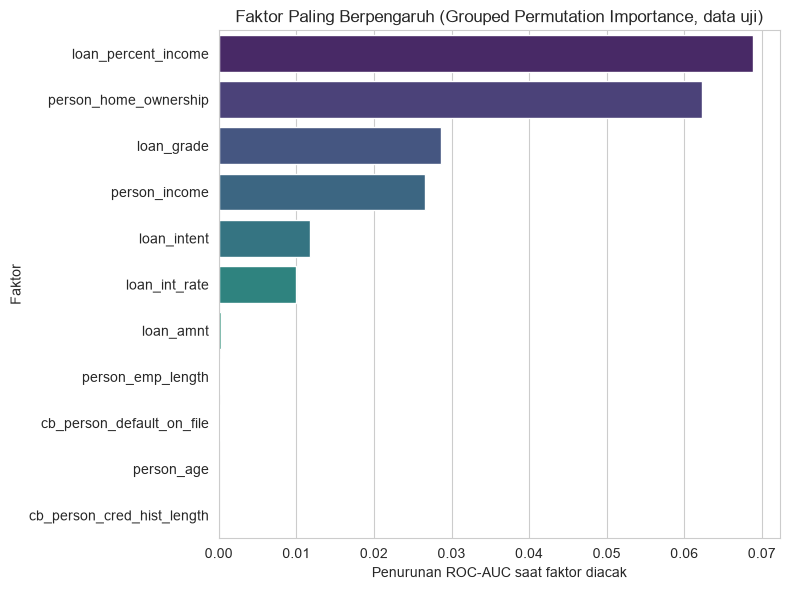

In [30]:
# visualisasi grouped permutation importance
plt.figure(figsize=(8, 6))
sns.barplot(data=importance_df, y='Faktor', x='Penurunan_AUC', hue='Faktor', palette='viridis', legend=False)
plt.title('Faktor Paling Berpengaruh (Grouped Permutation Importance, data uji)')
plt.xlabel('Penurunan ROC-AUC saat faktor diacak'); plt.tight_layout(); plt.show()

In [31]:
# pembanding: rata-rata fitur per kelas (efek searah/tidak), dalam satuan simpangan baku
Z = df_enc.drop(columns='loan_status')
std_diff = ((Z[y==1].mean() - Z[y==0].mean()) / Z.std()).rename('Selisih_rata2 (dlm std)').sort_values(key=abs, ascending=False)
display(std_diff.round(3).to_frame())

,Selisih_rata2 (dlm std)
loan_percent_income,0.950
loan_grade,0.874
loan_int_rate,0.782
person_home_ownership_RENT,0.614
person_income,-0.443
cb_person_default_on_file,0.422
person_home_ownership_OWN,-0.244
person_emp_length,-0.233
loan_amnt,0.206
loan_intent_VENTURE,-0.170


# 7. Simulasi Prediksi pada Sampel Kasus Nyata

Simulasi Pengujian Kasus Nyata (Studi Kasus Pemohon Kredit)

Untuk menguji kinerja model **Gaussian Naive Bayes** dalam skenario pengambilan keputusan nyata, dilakukan simulasi prediksi terhadap profil seorang calon peminjam dengan karakteristik sebagai berikut:

* **Profil Demografis & Pekerjaan:** Seorang pemohon berusia **25 tahun** (`person_age = 25`), saat ini tinggal di rumah sewa (`person_home_ownership = RENT`), dan baru memiliki pengalaman kerja selama **1 tahun** (`person_emp_length = 1.0`) dengan total pendapatan tahunan sebesar **$9.600** (`person_income = 9600`).
* **Riwayat Kredit:** Pemohon telah memiliki riwayat kredit selama **3 tahun** (`cb_person_cred_hist_length = 3`) dan belum pernah tercatat mengalami gagal bayar sebelumnya (`cb_person_default_on_file = N`).
* **Detail Pengajuan Pinjaman:** Pemohon mengajukan pinjaman sebesar **$5.500** (`loan_amnt = 5500`) untuk kebutuhan biaya pengobatan/medis (`loan_intent = MEDICAL`). Pinjaman tersebut masuk dalam kategori peringkat **Grade C** (`loan_grade = 2`) dengan tingkat suku bunga sebesar **12,87%** (`loan_int_rate = 12.87`), sehingga rasio jumlah pinjaman terhadap pendapatan tahunannya mencapai **57%** (`loan_percent_income = 0.57`).

In [23]:
# prediksi untuk pemohon hipotetis
final_model = make_pipeline().fit(X, y)

# Pemohon hipotetis. Semua kolom X dibuat 0 dulu, lalu hanya yang relevan diisi.
# Kategori acuan (MORTGAGE dan DEBTCONSOLIDATION) memang tidak punya kolom karena drop_first=True,
# jadi cukup dibiarkan 0 semua.
kasus = dict.fromkeys(X.columns, 0)
kasus.update({
    'person_age': 25,
    'person_income': 9600,
    'person_emp_length': 1.0,
    'loan_grade': 2,                  # Grade C
    'loan_amnt': 5500,
    'loan_int_rate': 12.87,
    'loan_percent_income': 0.57,
    'cb_person_default_on_file': 0,   # N
    'cb_person_cred_hist_length': 3,
    'person_home_ownership_RENT': 1,  # sewa
    'loan_intent_MEDICAL': 1,         # medis
})
sample_case = pd.DataFrame([kasus])[X.columns]

pred_proba = final_model.predict_proba(sample_case)[0]
pred_class = int(pred_proba[1] >= 0.5)

In [25]:
print('Hasil Prediksi Sampel Contoh:')
print(f"Hasil Klasifikasi : Kelas {pred_class} -> {'GAGAL BAYAR (Risiko Tinggi)' if pred_class == 1 else 'LANCAR (Risiko Rendah)'}")
print(f'Skor risiko       : Lancar (0) = {pred_proba[0]*100:.2f}% | Gagal Bayar (1) = {pred_proba[1]*100:.2f}%')

Hasil Prediksi Sampel Contoh:
Hasil Klasifikasi : Kelas 1 -> GAGAL BAYAR (Risiko Tinggi)
Skor risiko       : Lancar (0) = 0.00% | Gagal Bayar (1) = 100.00%


Skor GNB dibaca sebagai **skor peringkat risiko**, bukan peluang literal. Karena fitur saling berkorelasi dan ada fitur biner, angkanya sering mendekati 0 atau 100%.

# 8. Rekomendasi untuk Manajemen

In [26]:
g = df_clean.groupby('loan_grade')['loan_status'].mean()*100
h = df_clean.groupby('person_home_ownership')['loan_status'].mean()*100
it = df_clean.groupby('loan_intent')['loan_status'].mean()*100
dti = df_clean.groupby('dti_bin', observed=True)['loan_status'].mean()*100
rec_m = summary.loc['recall','Rata-rata']*100; prec = summary.loc['precision','Rata-rata']*100
auc = summary.loc['roc_auc','Rata-rata']; top = importance_df['Faktor'].head(3).tolist()

rekomendasi = pd.DataFrame({
 'Temuan': [
  f"3 faktor teratas model: {', '.join(top)}",
  f"Gagal bayar Grade A-C: {g.loc[['A','B','C']].min():.1f}-{g.loc[['A','B','C']].max():.1f}%, naik ke {g.loc['D']:.1f}% pada Grade D dan {g.loc['G']:.1f}% pada Grade G",
  f"Rasio pinjaman/pendapatan {dti.index[0]}: {dti.iloc[0]:.1f}% gagal bayar; {dti.index[-1]}: {dti.iloc[-1]:.1f}%",
  f"Penyewa (RENT) {h.loc['RENT']:.1f}% vs pemilik rumah (OWN) {h.loc['OWN']:.1f}% dan KPR (MORTGAGE) {h.loc['MORTGAGE']:.1f}%",
  f"Tujuan paling berisiko: {it.idxmax()} ({it.max():.1f}%); paling rendah: {it.idxmin()} ({it.min():.1f}%)",
  f"GNB: ROC-AUC {auc:.3f}, Recall {rec_m:.1f}%, Precision {prec:.1f}%"],
 'Rekomendasi': [
  "Jadikan faktor teratas sebagai kriteria utama penilaian dan pantau secara berkala.",
  "Perketat persetujuan mulai Grade D (agunan tambahan, limit lebih rendah, atau persetujuan berjenjang).",
  "Tetapkan batas rasio pinjaman/pendapatan pada titik di mana gagal bayar mulai melonjak (lihat tabel Langkah 3).",
  "Perlakukan status RENT sebagai sinyal risiko tambahan, bukan alasan tolak otomatis; kombinasikan dengan rasio dan grade.",
  "Terapkan pemeriksaan tambahan pada tujuan pinjaman berisiko tinggi dan evaluasi ulang kebijakan produknya.",
  f"Pakai model sebagai *early screening* (pemilah awal); keputusan akhir tetap melibatkan analis. Sekitar {100-prec:.0f}% pemohon yang ditandai berisiko ternyata lancar (false alarm)."]})
display(rekomendasi)

,Temuan,Rekomendasi
0,"3 faktor teratas model: loan_percent_income, p...",Jadikan faktor teratas sebagai kriteria utama ...
1,"Gagal bayar Grade A-C: 9.8-20.3%, naik ke 56.8...",Perketat persetujuan mulai Grade D (agunan tam...
2,"Rasio pinjaman/pendapatan (-0.001, 0.1]: 11.0%...",Tetapkan batas rasio pinjaman/pendapatan pada ...
3,Penyewa (RENT) 31.0% vs pemilik rumah (OWN) 7....,Perlakukan status RENT sebagai sinyal risiko t...
4,Tujuan paling berisiko: DEBTCONSOLIDATION (28....,Terapkan pemeriksaan tambahan pada tujuan pinj...
5,"GNB: ROC-AUC 0.851, Recall 67.3%, Precision 58.3%",Pakai model sebagai *early screening* (pemilah...


## Keterbatasan Model
- Dataset hanya berisi peminjam yang **sudah disetujui** (*selection bias*), sehingga model tidak mengetahui perilaku pemohon yang ditolak.
- `loan_grade` dan `loan_int_rate` ditetapkan oleh pemberi pinjaman sendiri, jadi keduanya sebagian mencerminkan penilaian risiko yang sudah ada, bukan sekadar sifat peminjam.
- Asumsi independensi dan normalitas GNB tidak sepenuhnya terpenuhi. Model lain (Logistic Regression, Random Forest, Gradient Boosting) layak dijadikan pembanding.
- Dataset tidak memuat tenor, agunan, atau data makro, sehingga rekomendasi terbatas pada variabel yang tersedia.

# 9. Analisis Laporan Sensitivitas Cleaning


In [32]:
KONSISTENSI = 'loan_percent_income tidak sesuai loan_amnt/income'
d0 = df.drop_duplicates()
flag0 = audit_rules(d0)[KONSISTENSI]

# (a) Komposisi baris yang ditandai aturan
print('Baris ditandai:', int(flag0.sum()), f'({flag0.mean()*100:.2f}% dari data tanpa duplikat)')
print('\nStatus pinjaman baris ditandai:'); print(d0[flag0]['loan_status'].value_counts().rename({0: 'Lancar', 1: 'Gagal bayar'}))
print('\nTujuan pinjaman baris ditandai:'); print(d0[flag0]['loan_intent'].value_counts())
print('\nGrade baris ditandai:'); print(d0[flag0]['loan_grade'].value_counts().sort_index())
print(f"\nPembanding, proporsi gagal bayar seluruh data tanpa duplikat: {d0['loan_status'].mean()*100:.2f}%")

Baris ditandai: 387 (1.19% dari data tanpa duplikat)

Status pinjaman baris ditandai:
loan_status
Gagal bayar    387
Name: count, dtype: int64

Tujuan pinjaman baris ditandai:
loan_intent
MEDICAL    387
Name: count, dtype: int64

Grade baris ditandai:
loan_grade
A     19
B     45
C     37
D    190
E     67
F     26
G      3
Name: count, dtype: int64

Pembanding, proporsi gagal bayar seluruh data tanpa duplikat: 21.87%


In [ ]:
# Model dengan dan tanpa aturan konsistensi
def siapkan(drop_rules):
    d = df.copy()
    for c in ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']:
        d[c] = d[c].astype(str).str.strip().str.upper()
    d = d.drop_duplicates()
    for r in drop_rules:
        d = d[~audit_rules(d)[r]]
    flag = audit_rules(d)[KONSISTENSI].values          # True = baris yang ditandai aturan konsistensi
    d['loan_grade'] = d['loan_grade'].map({'A':0,'B':1,'C':2,'D':3,'E':4,'F':5,'G':6})
    d['cb_person_default_on_file'] = d['cb_person_default_on_file'].map({'N':0,'Y':1})
    d = pd.get_dummies(d, columns=['person_home_ownership', 'loan_intent'], drop_first=True, dtype=int).reset_index(drop=True)
    return d.drop(columns='loan_status'), d['loan_status'], flag

skenario = {'Dengan aturan cleaning': DROP_RULES,
            'Tanpa aturan cleaning': [r for r in DROP_RULES if r != KONSISTENSI]}
hasil, data_skenario = {}, {}
for nama, aturan in skenario.items():
    Xs, ys, fl = siapkan(aturan)
    data_skenario[nama] = (Xs, ys, fl)
    s = cross_validate(make_pipeline(), Xs, ys, cv=skf, scoring=scoring)
    hasil[nama] = {'Jumlah data': len(ys), 'Gagal bayar (%)': ys.mean() * 100,
                   'Accuracy (%)': s['test_accuracy'].mean() * 100, 'Precision (%)': s['test_precision'].mean() * 100,
                   'Recall (%)': s['test_recall'].mean() * 100, 'F1-score (%)': s['test_f1'].mean() * 100,
                   'ROC-AUC': s['test_roc_auc'].mean(), 'Average Precision': s['test_average_precision'].mean(),
                   'Baseline AP': ys.mean()}
tabel_sens = pd.DataFrame(hasil).round(4)
tabel_sens['Selisih (tanpa - dengan)'] = (tabel_sens['Tanpa aturan cleaning'] - tabel_sens['Dengan aturan cleaning']).round(4)
display(tabel_sens)

,Dengan aturan cleaning,Tanpa aturan cleaning,Selisih (tanpa - dengan)
Jumlah data,32020.0000,32407.0000,387.0000
Gagal bayar (%),20.9275,21.8718,0.9443
Accuracy (%),83.0606,82.2476,-0.8130
Precision (%),58.2592,58.1447,-0.1145
Recall (%),67.2890,67.3531,0.0641
F1-score (%),62.4315,62.4005,-0.0310
ROC-AUC,0.8511,0.8487,-0.0024
Average Precision,0.6317,0.6379,0.0062
Baseline AP,0.2093,0.2187,0.0094


In [ ]:
# Diagnostik: bagaimana model yang dilatih pada data bersih memperlakukan baris yang dibuang aturan?
Xa, ya, fa = data_skenario['Tanpa aturan cleaning']
if fa.sum() > 0:
    m = make_pipeline().fit(Xa[~fa], ya[~fa])            
    p_flag = m.predict_proba(Xa[fa])[:, 1]
    print(f'Baris ditandai: {fa.sum()} | berlabel gagal bayar: {int(ya[fa].sum())} ({ya[fa].mean()*100:.1f}%)')
    print(f'Model (dilatih tanpa baris itu) memprediksi gagal bayar pada {(p_flag >= 0.5).mean()*100:.1f}% dari baris tersebut')
    print(f'Rata-rata rasio pinjaman/pendapatan baris ditandai: {Xa[fa]["loan_percent_income"].mean():.3f} '
          f'| baris lain: {Xa[~fa]["loan_percent_income"].mean():.3f}')
else:
    print('Tidak ada baris yang ditandai aturan konsistensi.')

Baris ditandai: 387 | berlabel gagal bayar: 387 (100.0%)
Model (dilatih tanpa baris itu) memprediksi gagal bayar pada 64.6% dari baris tersebut
Rata-rata rasio pinjaman/pendapatan baris ditandai: 0.187 | baris lain: 0.170
